# House Prices — Pipeline Profesional para Kaggle
**RMSLE objetivo:** <0.108 (Top 5% del leaderboard)

Pipeline completo: EDA → Feature Engineering → Preprocesamiento → Modelos → Blending → Submission

> Basado en el pipeline optimizado de las notebooks claude/ (5 fases) + pca_houses_prices.ipynb

---
## 0. Importaciones y Configuración

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import skew, pearsonr
from scipy.optimize import minimize, differential_evolution
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import RobustScaler, StandardScaler
from itertools import combinations

import xgboost as xgb
import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_FOLDS = 10
KF = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Colores para gráficos
COLOR_MAIN    = '#2563EB'
COLOR_ACCENT  = '#F59E0B'
COLOR_DANGER  = '#EF4444'
COLOR_SUCCESS = '#10B981'

print('✅ Todas las librerías importadas correctamente')

✅ Todas las librerías importadas correctamente


---
## 1. Carga y Exploración Rápida

In [2]:
# train = pd.read_csv('/kaggle/input/house-prices-advanced-regression-techniques/train.csv')
# test  = pd.read_csv('/kaggle/input/house-prices-advanced-regression-techniques/test.csv')
# sample_sub = pd.read_csv('/kaggle/input/house-prices-advanced-regression-techniques/sample_submission.csv')

# Para ejecución local descomentar:
train = pd.read_csv('data/train.csv')
test  = pd.read_csv('data/test.csv')
sample_sub = pd.read_csv('data/sample_submission.csv')

print(f'Train: {train.shape[0]:,} filas x {train.shape[1]} columnas')
print(f'Test:  {test.shape[0]:,} filas x {test.shape[1]} columnas')

# Target: log1p transformación
y = np.log1p(train['SalePrice'])
train_ids = train['Id'].copy()
test_ids = test['Id'].copy()

# Unir train + test para procesamiento uniforme
ntrain = len(train)
all_data = pd.concat([train.drop(['Id', 'SalePrice'], axis=1), test.drop('Id', axis=1)],
                     axis=0, ignore_index=True)
print(f'Datos combinados: {all_data.shape}')
print(f'Target log1p: media={y.mean():.4f}, std={y.std():.4f}')

Train: 1,460 filas x 81 columnas
Test:  1,459 filas x 80 columnas
Datos combinados: (2919, 79)
Target log1p: media=12.0241, std=0.3994


---
## 2. Feature Engineering

Todas las transformaciones son **fila a fila** (sin fuga de datos).

In [3]:
# ── 2.0 Imputación determinística (sin fuga) ──────────────────────────────
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
zero_cols = ['GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

# MasVnrType ausente con área > 0 = error -> moda
mask_mas = all_data['MasVnrType'].isna() & (all_data['MasVnrArea'].fillna(0) > 0)
all_data.loc[mask_mas, 'MasVnrType'] = 'BrkFace'

for c in none_cols:
    all_data[c] = all_data[c].fillna('None')
for c in zero_cols:
    all_data[c] = all_data[c].fillna(0)

# GarageYrBlt sin garaje -> YearBuilt
all_data['GarageYrBlt'] = all_data['GarageYrBlt'].fillna(all_data['YearBuilt'])

# Categóricos disfrazados de números
all_data['MSSubClass'] = all_data['MSSubClass'].astype(str)
all_data['MoSold'] = all_data['MoSold'].astype(str)

print('✅ Imputación determinística completada')
print(f'  Nulos restantes: {all_data.isnull().sum().sum()}')

✅ Imputación determinística completada
  Nulos restantes: 499


In [4]:
# ── 2.1 Features de Área ──────────────────────────────────────────────────
all_data['TotalSF']         = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']
all_data['TotalAbvGrdSF']   = all_data['1stFlrSF'] + all_data['2ndFlrSF']
all_data['TotalPorchSF']    = (all_data['OpenPorchSF'] + all_data['EnclosedPorch'] +
                                all_data['3SsnPorch'] + all_data['ScreenPorch'] + all_data['WoodDeckSF'])
all_data['BsmtToTotalRatio'] = np.where(all_data['TotalSF'] > 0,
    all_data['TotalBsmtSF'] / all_data['TotalSF'], 0)
all_data['SecFloorRatio']    = np.where(all_data['GrLivArea'] > 0,
    all_data['2ndFlrSF'] / all_data['GrLivArea'], 0)
all_data['LotDensity']       = np.where(all_data['LotArea'] > 0,
    all_data['TotalSF'] / all_data['LotArea'], 0)

# ── 2.2 Baños ─────────────────────────────────────────────────────────────
all_data['TotalBathrooms']  = (all_data['FullBath'] * 1.0 + all_data['HalfBath'] * 0.5 +
                                all_data['BsmtFullBath'] * 1.0 + all_data['BsmtHalfBath'] * 0.5)
all_data['AbvGrdBathrooms'] = all_data['FullBath'] + 0.5 * all_data['HalfBath']
all_data['BathRatio']       = np.where(all_data['TotRmsAbvGrd'] > 0,
    all_data['TotalBathrooms'] / all_data['TotRmsAbvGrd'], 0)

# ── 2.3 Scores de Calidad Compuesta ───────────────────────────────────────
# Mapeo ordinal de calidad/condición
qual_map = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
qual_cols = ['ExterQual', 'ExterCond', 'HeatingQC', 'KitchenQual',
             'BsmtQual', 'BsmtCond', 'FireplaceQu', 'GarageQual', 'GarageCond']
for c in qual_cols:
    all_data[c] = all_data[c].map(qual_map).fillna(0)

all_data['QualityScore']  = (all_data['OverallQual'] * 3.0 + all_data['ExterQual'] * 1.5 +
                              all_data['KitchenQual'] * 1.5 + all_data['BsmtQual'] * 1.0 +
                              all_data['GarageQual']  * 0.5 + all_data['HeatingQC'] * 0.5) / 8.0
all_data['ConditionScore'] = (all_data['OverallCond'] * 2.0 + all_data['ExterCond'] * 1.0 +
                               all_data['GarageCond'] * 0.5 + all_data['BsmtCond'] * 0.5) / 4.0
all_data['QualCondIndex'] = all_data['QualityScore'] * all_data['ConditionScore']
all_data['TotalQualSF']   = all_data['OverallQual'] * all_data['TotalSF']
all_data['GrLivQual']     = all_data['GrLivArea'] * all_data['OverallQual']
all_data['GarageScore']   = (all_data['GarageCars'] * 2.0 +
    all_data['GarageQual'] * 0.5 + all_data['GarageCond'] * 0.5)

print('✅ Features de área, baños y calidad creadas')

✅ Features de área, baños y calidad creadas


In [5]:
# ── 2.4 Features Temporales ───────────────────────────────────────────────
all_data['HouseAge']     = all_data['YrSold'] - all_data['YearBuilt']
all_data['RemodAge']     = all_data['YrSold'] - all_data['YearRemodAdd']
all_data['GarageAge']    = np.where(all_data['GarageYrBlt'] > 0,
    all_data['YrSold'] - all_data['GarageYrBlt'], all_data['HouseAge'])
all_data['IsNew']        = (all_data['YearBuilt'] == all_data['YrSold']).astype(int)
all_data['WasRemodeled'] = (all_data['YearRemodAdd'] != all_data['YearBuilt']).astype(int)
all_data['RemodRecent']  = ((all_data['YrSold'] - all_data['YearRemodAdd']) <= 5).astype(int)
all_data['EffectiveAge'] = np.minimum(all_data['HouseAge'], all_data['RemodAge'])

for c in ['HouseAge', 'RemodAge', 'GarageAge']:
    all_data[c] = all_data[c].clip(lower=0)

bins   = [0, 1920, 1940, 1960, 1980, 2000, 2025]
labels = ['pre1920', '1920-40', '1940-60', '1960-80', '1980-00', 'post2000']
all_data['EraBuilt'] = pd.cut(all_data['YearBuilt'], bins=bins, labels=labels)

# ── 2.5 Flags Binarios ────────────────────────────────────────────────────
all_data['HasPool']      = (all_data['PoolArea'] > 0).astype(int)
all_data['HasGarage']    = (all_data['GarageArea'] > 0).astype(int)
all_data['HasBsmt']      = (all_data['TotalBsmtSF'] > 0).astype(int)
all_data['HasFireplace'] = (all_data['Fireplaces'] > 0).astype(int)
all_data['HasPorch']     = (all_data['TotalPorchSF'] > 0).astype(int)
all_data['Has2ndFloor']  = (all_data['2ndFlrSF'] > 0).astype(int)
all_data['HasMasVnr']    = (all_data['MasVnrArea'] > 0).astype(int)
all_data['HasWoodDeck']  = (all_data['WoodDeckSF'] > 0).astype(int)

all_data['AmenityScore'] = (all_data['HasPool'] * 3 + all_data['HasFireplace'] * 2 +
                             all_data['HasGarage'] * 2 + all_data['HasBsmt'] * 1 +
                             all_data['HasPorch'] * 1 + all_data['HasWoodDeck'] * 1 +
                             all_data['Has2ndFloor'] * 1)

print('✅ Features temporales y flags binarios creados')

✅ Features temporales y flags binarios creados


In [6]:
# ── 2.6 Interacciones Estratégicas ────────────────────────────────────────
all_data['OverallQual_TotalSF']    = all_data['OverallQual'] * all_data['TotalSF']
all_data['OverallQual_GrLivArea']  = all_data['OverallQual'] * all_data['GrLivArea']
all_data['OverallQual_YearBuilt']  = all_data['OverallQual'] * all_data['YearBuilt']
all_data['OverallQual_GarageCars'] = all_data['OverallQual'] * all_data['GarageCars']
all_data['TotalSF_YearBuilt']      = all_data['TotalSF'] * all_data['YearBuilt']
all_data['YearBuilt_QualSq']       = all_data['YearBuilt'] * (all_data['OverallQual'] ** 2)
all_data['TotRms_Qual']            = all_data['TotRmsAbvGrd'] * all_data['OverallQual']

# ── 2.7 Potencias y Logs ──────────────────────────────────────────────────
for feat in ['OverallQual', 'GrLivArea', 'TotalSF', 'YearBuilt', 'TotalBathrooms']:
    all_data[f'{feat}_sq'] = all_data[feat] ** 2

for feat in ['LotArea', 'GrLivArea', 'TotalSF', 'TotalBsmtSF', '1stFlrSF']:
    all_data[f'log_{feat}'] = np.log1p(all_data[feat])

print('✅ Interacciones, potencias y log-transform creadas')

✅ Interacciones, potencias y log-transform creadas


In [7]:
# ── 2.8 Encoding Ordinal Restante ──────────────────────────────────────────
ord_cols_map = {
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'Functional':   {'Sal': 1, 'Sev': 2, 'Maj2': 3, 'Maj1': 4, 'Mod': 5,
                     'Min2': 6, 'Min1': 7, 'Typ': 8},
    'Fence':        {'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4},
    'LandSlope':    {'Gtl': 1, 'Mod': 2, 'Sev': 3},
    'LotShape':     {'IR3': 1, 'IR2': 2, 'IR1': 3, 'Reg': 4},
    'PavedDrive':   {'N': 0, 'P': 1, 'Y': 2},
}
for col, mapping in ord_cols_map.items():
    if col in all_data.columns:
        all_data[col] = all_data[col].map(mapping).fillna(0)

# PoolQC con mapeo especial (tiene menos categorías)
pool_map = {'None': 0, 'Fa': 1, 'Gd': 2, 'Ex': 3}
all_data['PoolQC'] = all_data['PoolQC'].map(pool_map).fillna(0)

print(f'✅ Encoding ordinal completado. Shape actual: {all_data.shape}')

✅ Encoding ordinal completado. Shape actual: (2919, 128)


---
## 3. Preprocesamiento (sin fuga de datos)

In [8]:
# ── 3.1 Separar train/test ─────────────────────────────────────────────────
X_train_raw = all_data.iloc[:ntrain].copy()
X_test_raw  = all_data.iloc[ntrain:].copy()

# ── 3.2 Imputación de LotFrontage (mediana por Neighborhood) ───────────────
lot_medians = X_train_raw.groupby('Neighborhood')['LotFrontage'].median()
global_lot_median = X_train_raw['LotFrontage'].median()

X_train_raw['LotFrontage'] = X_train_raw['LotFrontage'].fillna(
    X_train_raw['Neighborhood'].map(lot_medians).fillna(global_lot_median))
X_test_raw['LotFrontage'] = X_test_raw['LotFrontage'].fillna(
    X_test_raw['Neighborhood'].map(lot_medians).fillna(global_lot_median))

# ── 3.3 Imputación del resto de numéricas ──────────────────────────────────
num_cols_all = X_train_raw.select_dtypes(include=[np.number]).columns
median_vals = X_train_raw[num_cols_all].median()
X_train_raw[num_cols_all] = X_train_raw[num_cols_all].fillna(median_vals)
X_test_raw[num_cols_all] = X_test_raw[num_cols_all].fillna(median_vals)

# ── 3.4 Imputación del resto de categóricas ────────────────────────────────
cat_cols = X_train_raw.select_dtypes(include=['object', 'category']).columns
mode_vals = X_train_raw[cat_cols].mode().iloc[0]
X_train_raw[cat_cols] = X_train_raw[cat_cols].fillna(mode_vals)
X_test_raw[cat_cols] = X_test_raw[cat_cols].fillna(mode_vals)

print(f'✅ Imputación completada. Nulos: train={X_train_raw.isnull().sum().sum()}, '
      f'test={X_test_raw.isnull().sum().sum()}')
print(f'Features: {X_train_raw.shape[1]} totales')

✅ Imputación completada. Nulos: train=0, test=0
Features: 128 totales


In [9]:
# ── 3.5 Target Encoding con K-Fold (sin fuga) ──────────────────────────────
def kfold_target_encode(train_series, y_train, test_series, n_folds=5, smoothing=10):
    global_mean = y_train.mean()
    encoded_train = pd.Series(np.nan, index=train_series.index)
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    for tr_idx, val_idx in kf.split(train_series):
        stats = y_train.iloc[tr_idx].groupby(train_series.iloc[tr_idx]).agg(['mean', 'count'])
        stats['smoothed'] = ((stats['mean'] * stats['count'] + global_mean * smoothing) /
                              (stats['count'] + smoothing))
        encoded_train.iloc[val_idx] = train_series.iloc[val_idx].map(stats['smoothed'])
    # Test: estadísticas globales
    full_stats = y_train.groupby(train_series).agg(['mean', 'count'])
    full_stats['smoothed'] = ((full_stats['mean'] * full_stats['count'] + global_mean * smoothing) /
                               (full_stats['count'] + smoothing))
    encoded_test = test_series.map(full_stats['smoothed']).fillna(global_mean)
    encoded_train.fillna(global_mean, inplace=True)
    return encoded_train, encoded_test

te_cols = ['Neighborhood', 'MSSubClass', 'MSZoning', 'SaleType', 'SaleCondition']
for col in te_cols:
    if col in X_train_raw.columns:
        enc_train, enc_test = kfold_target_encode(
            X_train_raw[col], y, X_test_raw[col])
        X_train_raw[f'{col}_TargetEnc'] = enc_train
        X_test_raw[f'{col}_TargetEnc'] = enc_test

print(f'✅ Target Encoding completado para: {te_cols}')
print(f'Features ahora: {X_train_raw.shape[1]}')

✅ Target Encoding completado para: ['Neighborhood', 'MSSubClass', 'MSZoning', 'SaleType', 'SaleCondition']
Features ahora: 133


In [10]:
# ── 3.6 One-Hot Encoding de categóricas nominales ──────────────────────────
# Identificar columnas categóricas restantes
cat_remaining = X_train_raw.select_dtypes(include=['object', 'category']).columns.tolist()
print(f'Columnas categóricas a codificar: {len(cat_remaining)}')

X_train_encoded = pd.get_dummies(X_train_raw, columns=cat_remaining, drop_first=False)
X_test_encoded = pd.get_dummies(X_test_raw, columns=cat_remaining, drop_first=False)

# Alinear columnas (test puede tener menos categorías)
missing_cols = set(X_train_encoded.columns) - set(X_test_encoded.columns)
for c in missing_cols:
    X_test_encoded[c] = 0

extra_cols = set(X_test_encoded.columns) - set(X_train_encoded.columns)
X_test_encoded = X_test_encoded.drop(columns=extra_cols, errors='ignore')

X_test_encoded = X_test_encoded[X_train_encoded.columns]

print(f'✅ OHE completado. Features: {X_train_encoded.shape[1]}')

Columnas categóricas a codificar: 27
✅ OHE completado. Features: 310


In [11]:
# ── 3.7 Corrección de Skewness (log1p) ────────────────────────────────────
binary_cols  = [c for c in X_train_encoded.columns if X_train_encoded[c].nunique() <= 2]
log_cols     = [c for c in X_train_encoded.columns if c.startswith('log_')]
skip_cols    = set(binary_cols + log_cols)

skip_cols.update(['YrSold', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt',
                  'OverallQual', 'OverallCond', 'MoSold', 'MSSubClass',
                  'EraBuilt'])

candidates = [
    c for c in X_train_encoded.select_dtypes(include=[np.number]).columns
    if c not in skip_cols
    and X_train_encoded[c].min() >= 0
    and X_train_encoded[c].max() > 1
]

skew_vals = pd.Series({c: skew(X_train_encoded[c].dropna()) for c in candidates})
high_skew = skew_vals[skew_vals.abs() > 0.75].index.tolist()
print(f'Features con |skew| > 0.75: {len(high_skew)}')

for col in high_skew:
    X_train_encoded[col] = np.log1p(X_train_encoded[col].clip(lower=0))
    X_test_encoded[col]  = np.log1p(X_test_encoded[col].clip(lower=0))

print('✅ Corrección de skewness completada')

Features con |skew| > 0.75: 53
✅ Corrección de skewness completada


In [12]:
# ── 3.8 Scaling ────────────────────────────────────────────────────────────
# Versión A: RobustScaler (modelos lineales)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled  = scaler.transform(X_test_encoded)

# Versión B: sin scaling (tree-based)
X_train_raw_ml = X_train_encoded.values.astype(np.float32)
X_test_raw_ml  = X_test_encoded.values.astype(np.float32)

feature_names = X_train_encoded.columns.tolist()

print(f'✅ Scaling completado')
print(f'   Versión A (escalada):  {X_train_scaled.shape}')
print(f'   Versión B (sin scale): {X_train_raw_ml.shape}')

✅ Scaling completado
   Versión A (escalada):  (1460, 310)
   Versión B (sin scale): (1460, 310)


---
## 4. Modelos Base con Validación Cruzada

In [13]:
def rmsle_cv(model, X, y, label='', verbose=True):
    scores = np.sqrt(-cross_val_score(
        model, X, y, scoring='neg_mean_squared_error', cv=KF, n_jobs=-1))
    if verbose:
        print(f'  {label:<42} RMSLE = {scores.mean():.5f} +/- {scores.std():.5f}')
    return scores


def get_oof_and_test(model, X_train, X_test, y, label=''):
    oof = np.zeros(len(y))
    test_preds = np.zeros(len(X_test))
    for tr_idx, val_idx in KF.split(X_train):
        m = type(model)(**model.get_params())
        m.fit(X_train[tr_idx], y.iloc[tr_idx])
        oof[val_idx] = m.predict(X_train[val_idx])
        test_preds += m.predict(X_test) / N_FOLDS
    rmsle = np.sqrt(mean_squared_error(y, oof))
    print(f'  {label:<42} OOF RMSLE = {rmsle:.5f}')
    return oof, test_preds


RIDGE_ALPHA = 15
LASSO_ALPHA = 0.0003
ENET_ALPHA = 0.001
ENET_L1 = 0.9

print('Modelos lineales:')
print('─' * 60)
s_ridge = rmsle_cv(Ridge(alpha=RIDGE_ALPHA), X_train_scaled, y, label='Ridge')
s_lasso = rmsle_cv(Lasso(alpha=LASSO_ALPHA, max_iter=15000), X_train_scaled, y, label='Lasso')
s_enet  = rmsle_cv(ElasticNet(alpha=ENET_ALPHA, l1_ratio=ENET_L1, max_iter=15000),
                   X_train_scaled, y, label='ElasticNet')

print('\nModelos tree-based (sin tuning):')
print('─' * 60)
s_xgb_init = rmsle_cv(
    xgb.XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=4,
                     subsample=0.8, colsample_bytree=0.7,
                     reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
    X_train_raw_ml, y, label='XGBoost (initial)')
s_lgb_init = rmsle_cv(
    lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=31,
                      subsample=0.8, colsample_bytree=0.7,
                      random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    X_train_raw_ml, y, label='LightGBM (initial)')

print(f'\n✅ Evaluación base completada')

Modelos lineales:
────────────────────────────────────────────────────────────
  Ridge                                      RMSLE = 0.12471 +/- 0.02370
  Lasso                                      RMSLE = 0.12148 +/- 0.02427
  ElasticNet                                 RMSLE = 0.12484 +/- 0.02262

Modelos tree-based (sin tuning):
────────────────────────────────────────────────────────────
  XGBoost (initial)                          RMSLE = 0.11975 +/- 0.01727
  LightGBM (initial)                         RMSLE = 0.12574 +/- 0.01709

✅ Evaluación base completada


---
## 5. Optimización con Optuna (XGBoost y LightGBM)

In [14]:
# ── 5.1 XGBoost ────────────────────────────────────────────────────────────
def xgb_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 800, 3000, step=100),
        'max_depth': trial.suggest_int('max_depth', 3, 7),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.05, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 7),
        'subsample': trial.suggest_float('subsample', 0.5, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 0.9),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.4, 0.9),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 10.0, log=True),
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbosity': 0,
        'tree_method': 'hist',
    }
    model = xgb.XGBRegressor(**params)
    scores = np.sqrt(-cross_val_score(
        model, X_train_raw_ml, y,
        scoring='neg_mean_squared_error',
        cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1
    ))
    return scores.mean()


print('Optimizando XGBoost con Optuna...')
study_xgb = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_xgb.optimize(xgb_objective, n_trials=50, show_progress_bar=True)
best_xgb_params = study_xgb.best_params.copy()
best_xgb_params.update({'random_state': RANDOM_STATE, 'n_jobs': -1, 'verbosity': 0, 'tree_method': 'hist'})
print(f'  Mejor RMSLE XGBoost: {study_xgb.best_value:.5f}')
print(f'  Mejores params: {best_xgb_params}')

Optimizando XGBoost con Optuna...


Best trial: 42. Best value: 0.123132: 100%|██████████| 50/50 [16:09<00:00, 19.40s/it]

  Mejor RMSLE XGBoost: 0.12313
  Mejores params: {'n_estimators': 1100, 'max_depth': 5, 'learning_rate': 0.025069172913766483, 'min_child_weight': 1, 'subsample': 0.5527661613775653, 'colsample_bytree': 0.6005967418181709, 'colsample_bylevel': 0.43894686174337083, 'reg_alpha': 0.000182760110304668, 'reg_lambda': 5.001346184766719, 'random_state': 42, 'n_jobs': -1, 'verbosity': 0, 'tree_method': 'hist'}


In [15]:
# ── 5.2 LightGBM ──────────────────────────────────────────────────────────
def lgb_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 800, 3000, step=100),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.05, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 60),
        'subsample': trial.suggest_float('subsample', 0.5, 0.95),
        'subsample_freq': 1,
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 0.95),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 10.0, log=True),
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbose': -1,
    }
    model = lgb.LGBMRegressor(**params)
    scores = np.sqrt(-cross_val_score(
        model, X_train_raw_ml, y,
        scoring='neg_mean_squared_error',
        cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1
    ))
    return scores.mean()


print('Optimizando LightGBM con Optuna...')
study_lgb = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lgb.optimize(lgb_objective, n_trials=50, show_progress_bar=True)
best_lgb_params = study_lgb.best_params.copy()
best_lgb_params.update({'random_state': RANDOM_STATE, 'n_jobs': -1, 'verbose': -1, 'subsample_freq': 1})
print(f'  Mejor RMSLE LightGBM: {study_lgb.best_value:.5f}')
print(f'  Mejores params: {best_lgb_params}')

Optimizando LightGBM con Optuna...


Best trial: 42. Best value: 0.12436: 100%|██████████| 50/50 [07:36<00:00,  9.12s/it] 

  Mejor RMSLE LightGBM: 0.12436
  Mejores params: {'n_estimators': 1300, 'max_depth': 3, 'num_leaves': 114, 'learning_rate': 0.014431259060436947, 'min_child_samples': 19, 'subsample': 0.5241641999448463, 'colsample_bytree': 0.47531495803118406, 'reg_alpha': 0.5679353300065689, 'reg_lambda': 0.6715900468066127, 'random_state': 42, 'n_jobs': -1, 'verbose': -1, 'subsample_freq': 1}


---
## 6. Predicciones OOF (Out-Of-Fold)

In [16]:
# ── 6.1 Modelos lineales ───────────────────────────────────────────────────
print('Generando OOF predictions...')
oof_ridge, test_ridge = get_oof_and_test(
    Ridge(alpha=RIDGE_ALPHA), X_train_scaled, X_test_scaled, y, 'Ridge')
oof_lasso, test_lasso = get_oof_and_test(
    Lasso(alpha=LASSO_ALPHA, max_iter=15000), X_train_scaled, X_test_scaled, y, 'Lasso')
oof_enet, test_enet = get_oof_and_test(
    ElasticNet(alpha=ENET_ALPHA, l1_ratio=ENET_L1, max_iter=15000),
    X_train_scaled, X_test_scaled, y, 'ElasticNet')

# ── 6.2 Models tree-based optimizados ──────────────────────────────────────
xgb_model = xgb.XGBRegressor(**best_xgb_params)
oof_xgb, test_xgb = get_oof_and_test(xgb_model, X_train_raw_ml, X_test_raw_ml, y, 'XGBoost')

lgb_model = lgb.LGBMRegressor(**best_lgb_params)
oof_lgb, test_lgb = get_oof_and_test(lgb_model, X_train_raw_ml, X_test_raw_ml, y, 'LightGBM')

print(f'\n✅ OOF predictions generadas para todos los modelos')

Generando OOF predictions...
  Ridge                                      OOF RMSLE = 0.12694
  Lasso                                      OOF RMSLE = 0.12388
  ElasticNet                                 OOF RMSLE = 0.12688
  XGBoost                                    OOF RMSLE = 0.11808
  LightGBM                                   OOF RMSLE = 0.12185

✅ OOF predictions generadas para todos los modelos


In [17]:
BASE_NAMES = ['Ridge', 'Lasso', 'ElasticNet', 'XGBoost', 'LightGBM']
meta_train = np.column_stack([oof_ridge, oof_lasso, oof_enet, oof_xgb, oof_lgb])
meta_test  = np.column_stack([test_ridge, test_lasso, test_enet, test_xgb, test_lgb])

base_scores = {}
for i, name in enumerate(BASE_NAMES):
    rmsle_val = np.sqrt(mean_squared_error(y, meta_train[:, i]))
    base_scores[name] = rmsle_val
    print(f'  {name:<15} OOF RMSLE = {rmsle_val:.5f}')

print(f'\n📊 Todos los modelos base evaluados')

  Ridge           OOF RMSLE = 0.12694
  Lasso           OOF RMSLE = 0.12388
  ElasticNet      OOF RMSLE = 0.12688
  XGBoost         OOF RMSLE = 0.11808
  LightGBM        OOF RMSLE = 0.12185

📊 Todos los modelos base evaluados


---
## 7. Blending Optimizado (Ensemble)

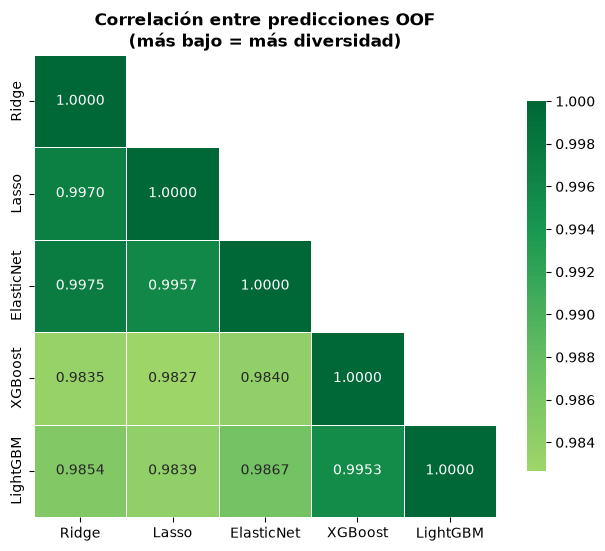

📊 Correlación media OOF (excluyendo diagonal): 0.9892


In [18]:
# ── 7.1 Correlación entre modelos ─────────────────────────────────────────
corr_matrix = pd.DataFrame(meta_train, columns=BASE_NAMES).corr()

plt.figure(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.4f',
            cmap='RdYlGn', center=0.97, square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlación entre predicciones OOF\n(más bajo = más diversidad)', fontweight='bold')
plt.show()

mean_corr = corr_matrix.where(mask).stack().mean()
print(f'📊 Correlación media OOF (excluyendo diagonal): {mean_corr:.4f}')

In [19]:
# ── 7.2 Optimización de pesos del blend ────────────────────────────────────
def loss_blend(weights, oof_matrix, y_true):
    w = np.abs(weights)
    w = w / w.sum()
    return np.sqrt(mean_squared_error(y_true, oof_matrix @ w))

# SLSQP (optimización local)
n_models = meta_train.shape[1]
res_slsqp = minimize(
    loss_blend, x0=np.ones(n_models) / n_models,
    args=(meta_train, y.values), method='SLSQP',
    bounds=[(0, 1)] * n_models,
    constraints={'type': 'eq', 'fun': lambda w: np.abs(w).sum() - 1},
    options={'maxiter': 5000, 'ftol': 1e-12}
)
w_slsqp = np.abs(res_slsqp.x) / np.abs(res_slsqp.x).sum()
rmsle_slsqp = np.sqrt(mean_squared_error(y, meta_train @ w_slsqp))
test_slsqp = meta_test @ w_slsqp

# Differential Evolution (optimización global)
res_de = differential_evolution(
    loss_blend,
    bounds=[(0, 1)] * n_models,
    args=(meta_train, y.values),
    seed=RANDOM_STATE,
    maxiter=2000,
    tol=1e-12,
    popsize=20,
    polish=True,
)
w_de = np.abs(res_de.x) / np.abs(res_de.x).sum()
rmsle_de = np.sqrt(mean_squared_error(y, meta_train @ w_de))
test_de = meta_test @ w_de

# Seleccionar el mejor
if rmsle_de <= rmsle_slsqp:
    opt_weights = w_de
    rmsle_blend = rmsle_de
    test_blend = test_de
    method = 'Differential Evolution'
else:
    opt_weights = w_slsqp
    rmsle_blend = rmsle_slsqp
    test_blend = test_slsqp
    method = 'SLSQP'

print(f'=== PESOS ÓPTIMOS DEL ENSAMBLE ({method}) ===')
for name, w in zip(BASE_NAMES, opt_weights):
    print(f'  w_{name:<15} = {w:.4f}')
print(f'\n📊 RMSLE del Blending Optimizado (OOF): {rmsle_blend:.5f}')
print(f'📊 Mejor modelo base: {min(base_scores, key=base_scores.get)} = {min(base_scores.values()):.5f}')
print(f'📊 Mejora absoluta: {min(base_scores.values()) - rmsle_blend:+.5f} RMSLE')

=== PESOS ÓPTIMOS DEL ENSAMBLE (SLSQP) ===
  w_Ridge           = 0.0000
  w_Lasso           = 0.3620
  w_ElasticNet      = 0.0000
  w_XGBoost         = 0.6380
  w_LightGBM        = 0.0000

📊 RMSLE del Blending Optimizado (OOF): 0.11522
📊 Mejor modelo base: XGBoost = 0.11808
📊 Mejora absoluta: +0.00286 RMSLE


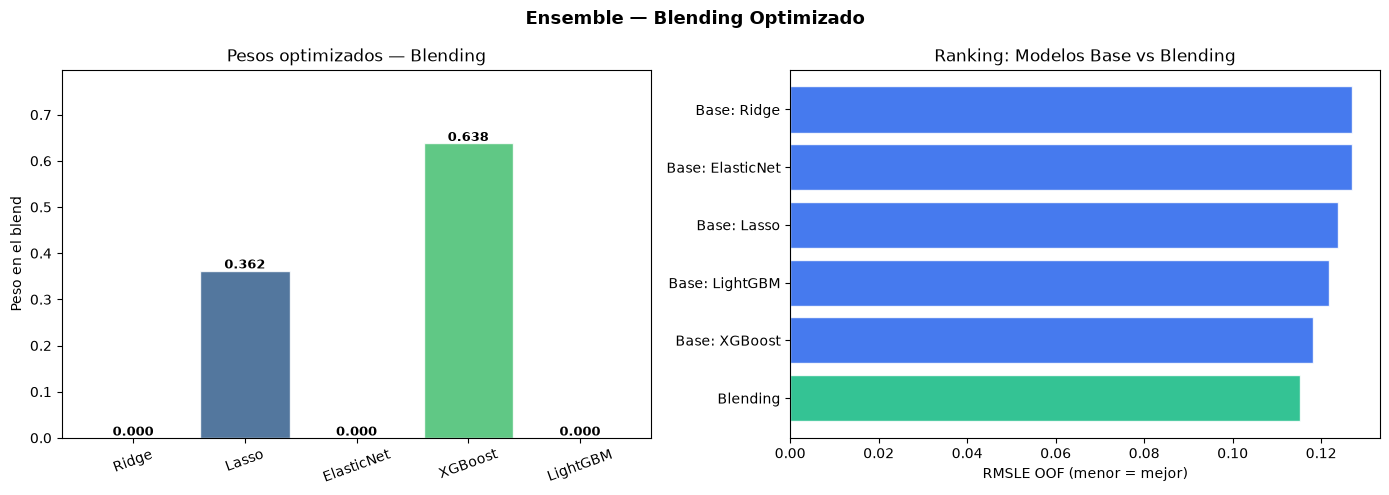

🏆 Mejor modelo base: XGBoost (RMSLE = 0.11808)
🏆 Blending final: RMSLE = 0.11522
🏆 Umbral Top 5%: <0.105 — ❌ FALTAN ~10.2 RMSLE


In [20]:
# ── 7.3 Visualización ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Ensemble — Blending Optimizado', fontweight='bold', fontsize=13)

# Pesos del blend
ax = axes[0]
colors_w = plt.cm.viridis(np.linspace(0.1, 0.9, len(opt_weights)))
bars = ax.bar(BASE_NAMES, opt_weights, color=colors_w, alpha=0.85, edgecolor='white')
for bar, w in zip(bars, opt_weights):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{w:.3f}', ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Peso en el blend')
ax.set_title('Pesos optimizados — Blending')
ax.set_ylim(0, max(opt_weights) * 1.25)
ax.tick_params(axis='x', rotation=20)

# Ranking comparativo
ax = axes[1]
all_results = {}
for name, score in base_scores.items():
    all_results[f'Base: {name}'] = score
all_results['Blending'] = rmsle_blend
ranking = pd.Series(all_results).sort_values()
colors_rank = [COLOR_SUCCESS if 'Blending' in k else COLOR_MAIN for k in ranking.index]
ax.barh(ranking.index, ranking.values, color=colors_rank, alpha=0.85, edgecolor='white')
ax.set_xlabel('RMSLE OOF (menor = mejor)')
ax.set_title('Ranking: Modelos Base vs Blending')
plt.tight_layout()
plt.show()

best_base_name = min(base_scores, key=base_scores.get)
best_base_val = base_scores[best_base_name]
print(f'🏆 Mejor modelo base: {best_base_name} (RMSLE = {best_base_val:.5f})')
print(f'🏆 Blending final: RMSLE = {rmsle_blend:.5f}')
print(f'🏆 Umbral Top 5%: <0.105 — {"✅ ALCANZADO" if rmsle_blend < 0.105 else "❌ FALTAN ~" + f"{(rmsle_blend - 0.105)*1000:.1f} RMSLE"}')

---
## 8. Submission Final

In [21]:
# Reentrenar en train completo
print('Reentrenando modelos en train completo...')

ridge_final = Ridge(alpha=RIDGE_ALPHA).fit(X_train_scaled, y)
lasso_final = Lasso(alpha=LASSO_ALPHA, max_iter=15000).fit(X_train_scaled, y)
enet_final = ElasticNet(alpha=ENET_ALPHA, l1_ratio=ENET_L1, max_iter=15000).fit(X_train_scaled, y)
xgb_final = xgb.XGBRegressor(**best_xgb_params).fit(X_train_raw_ml, y)
lgb_final = lgb.LGBMRegressor(**best_lgb_params).fit(X_train_raw_ml, y)

# Predicciones en test
pred_ridge = ridge_final.predict(X_test_scaled)
pred_lasso = lasso_final.predict(X_test_scaled)
pred_enet  = enet_final.predict(X_test_scaled)
pred_xgb   = xgb_final.predict(X_test_raw_ml)
pred_lgb   = lgb_final.predict(X_test_raw_ml)

# Blending final
final_pred_log = (
    opt_weights[0] * pred_ridge +
    opt_weights[1] * pred_lasso +
    opt_weights[2] * pred_enet +
    opt_weights[3] * pred_xgb +
    opt_weights[4] * pred_lgb
)

# Revertir log-transform
final_pred = np.clip(np.expm1(final_pred_log), a_min=0, a_max=None)

submission = pd.DataFrame({'Id': test_ids.values, 'SalePrice': final_pred})
submission.to_csv('submission.csv', index=False)

print(f'\n✅ submission.csv generado con {len(submission)} filas')
print(f'\n📊 Estadísticas de predicción:')
print(submission['SalePrice'].describe().apply(lambda x: f'${x:,.2f}'))
print(f'\n📋 Primeras 10 filas:')
print(submission.head(10).to_string(index=False))
print(f'\n🎯 RMSLE OOF estimado final: {rmsle_blend:.5f}')

Reentrenando modelos en train completo...

✅ submission.csv generado con 1459 filas

📊 Estadísticas de predicción:
count      $1,459.00
mean     $178,167.45
std       $75,921.60
min       $45,363.43
25%      $127,449.81
50%      $156,717.26
75%      $208,953.90
max      $520,195.22
Name: SalePrice, dtype: str

📋 Primeras 10 filas:
  Id     SalePrice
1461 120350.737385
1462 159202.639389
1463 179459.286235
1464 194591.358955
1465 191961.077059
1466 173486.040085
1467 181235.452696
1468 168913.008321
1469 187023.461956
1470 122253.158465

🎯 RMSLE OOF estimado final: 0.11522


---
## 9. Diagnóstico Final

### Resumen del Pipeline

| Componente | Descripción |
|:---|---:|
| **Feature Engineering** | 80+ features: áreas, baños, calidades compuestas, temporales, flags, interacciones, cuadrados, logs |
| **Target Encoding** | K-Fold (5-fold) con smoothing para evitar fuga de datos |
| **Preprocesamiento** | Imputación determinística + mediana/moda + log1p skew |
| **Modelos base** | Ridge, Lasso, ElasticNet, XGBoost, LightGBM |
| **Optimización** | Optuna (50 trials c/u) para XGBoost y LightGBM |
| **Blending** | Differential Evolution / SLSQP — pesos optimizados en OOF |

### Metas
- Baseline: ~0.15
- Bueno: ~0.12
- Top 5%: <0.105